<a href="https://colab.research.google.com/github/amsalu2212/DS-A4/blob/main/DS_Ass4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Name: Amsalu Tessema**
#**ID Number:2026A8000929002**
# Data Science Assignment 4 Model Comparison and Calibration Lab

**Dataset:** Wisconsin Breast Cancer Diagnostic (WDBC), accessed through Scikit-learn's packaged copy.  
**Positive class:** malignant (1); **negative class:** benign (0).

## Objectives of our assignment
- To Compare a strong simple baseline with more complex classifiers.
- To use a frozen split, identical stratified folds, fixed configurations, and paired predictions.
- To Prepare experimental report PR-AUC, ROC-AUC, calibration, Brier score, ECE, and uncertainty intervals.
- To inspect feature-based slices, false positives/false negatives, and a concrete counterexample.
- To select a decision threshold using explicit error costs and a human-review capacity constraint, then run sensitivity analysis.

## Data provenance
Original source: [UCI Machine Learning Repository — Breast Cancer Wisconsin (Diagnostic)]https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
Dear professor,to access the dataset, I used the notebook code `sklearn.datasets.load_breast_cancer(as_frame=True)`
Therefore, a separate data download is not needed. The source dataset is a small, curated diagnostic dataset; do not interpret results as evidence of clinical readiness.


## Frozen evaluation protocol

| Item | Frozen choice |
|---|---|
| Dataset version | Scikit-learn packaged WDBC copy; 569 rows, 30 numeric predictors |
| Target | malignant = 1, benign = 0 |
| Split | Stratified 80/20, seed 42 |
| CV | StratifiedKFold(5, shuffle=True, random_state=42) |
| Primary ranking metric | PR-AUC |
| Other metrics | ROC-AUC, Brier, 10-bin ECE, log loss, accuracy/precision/recall/F1 |
| Uncertainty | t intervals over five fold scores; percentile bootstrap intervals on holdout |
| Paired comparison | Same OOF rows resampled jointly for each model difference |
| Threshold policy | Minimize 5×FN + 1×FP subject to ≤20% training alerts |
| Calibration | Quantile-bin reliability diagram; Brier and ECE |
| Hyperparameter budget | Zero search trials; fixed configurations only |

## Execute the full experiment

It loads the public dataset, freezes the protocol, trains/evaluates all models, writes paired predictions and raw metrics, and generates PR/ROC, calibration, and cost figures.

The Five-fold confidence intervals are descriptive and have only four degrees of freedom. Bootstrap intervals quantify sampling variability conditional on this holdout; neither method accounts for dataset shift.

### Integrated source code — DS-A4: Model Comparison and Calibration Lab

In [ ]:
# Dataset: Wisconsin Breast Cancer Diagnostic (scikit-learn packaged copy)
# Positive class: malignant (1); negative class: benign (0)
# First import all necessary modules/libraries

from pathlib import Path
import json, platform, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy
from scipy.stats import t
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, precision_recall_curve, roc_curve
)
from sklearn.calibration import calibration_curve


### The following code also used for integrated source code Frozen protocol

In [ ]:
# -------------------------- Frozen protocol --------------------------
SEED = 42
N_SPLITS = 5
TEST_SIZE = 0.20
N_BOOT = 1000
N_ECE_BINS = 10
FN_COST = 5.0
FP_COST = 1.0
MAX_ALERT_RATE = 0.20
OUTPUT_DIR = Path("ds_a4_outputs")
FIG_DIR = OUTPUT_DIR / "figures"
OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

# The packaged sklearn copy makes this notebook reproducible without a data download.
# Dear professor Tijie, as I have mensioned before, the Original dataset source is : https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = (dataset.target == 0).astype(int).rename("malignant")  # sklearn: 0 malignant, 1 benign
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y
)

# Same frozen split and same StratifiedKFold folds for every candidate model.
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=1.0, max_iter=5000,
                                     class_weight="balanced", random_state=SEED))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=2,
        class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        learning_rate=0.08, max_iter=150, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=SEED
    ),
    "Dummy (stratified)": DummyClassifier(strategy="prior")
}

def ece_score(y_true, probability, n_bins=N_ECE_BINS):
    """Expected calibration error using fixed-width probability bins."""
    yy = np.asarray(y_true)
    pp = np.asarray(probability)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        mask = ((pp >= edges[i]) & (pp <= edges[i+1])) if i == n_bins-1 else (
            (pp >= edges[i]) & (pp < edges[i+1]))
        if mask.any():
            ece += mask.mean() * abs(yy[mask].mean() - pp[mask].mean())
    return float(ece)

def choose_threshold(y_true, probability, fn_cost=FN_COST,
                     fp_cost=FP_COST, max_alert_rate=MAX_ALERT_RATE):
    """Minimize empirical FN/FP cost subject to a maximum alert/review capacity."""
    yy, pp = np.asarray(y_true), np.asarray(probability)
    candidates = np.unique(np.r_[0.0, pp, 1.0])
    best = None
    for threshold in candidates:
        pred = (pp >= threshold).astype(int)
        alert_rate = pred.mean()
        if alert_rate <= max_alert_rate + 1e-12:
            tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
            cost = fn_cost * fn + fp_cost * fp
            # Tie-break toward the higher threshold (fewer alerts).
            candidate = (cost, -threshold, threshold)
            if best is None or candidate < best:
                best = candidate
    return float(best[2]) if best is not None else 1.0

def metrics_at_half(name, yy, pp):
    pred = (pp >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(yy, pred, labels=[0, 1]).ravel()
    return {
        "model": name, "ROC_AUC": roc_auc_score(yy, pp),
        "PR_AUC": average_precision_score(yy, pp),
        "Brier": brier_score_loss(yy, pp), "ECE_10bin": ece_score(yy, pp),
        "LogLoss": log_loss(yy, pp, labels=[0, 1]),
        "Accuracy_at_0.5": accuracy_score(yy, pred),
        "Precision_at_0.5": precision_score(yy, pred, zero_division=0),
        "Recall_at_0.5": recall_score(yy, pred, zero_division=0),
        "F1_at_0.5": f1_score(yy, pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

def bootstrap_ci(y_true, probability, metric, n_boot=N_BOOT, seed=SEED):
    """Percentile row-bootstrap CI; stratified by resampling rows with replacement."""
    yy, pp = np.asarray(y_true), np.asarray(probability)
    rng = np.random.default_rng(seed)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(yy), len(yy))
        if len(np.unique(yy[idx])) < 2:
            continue
        values.append(metric(yy[idx], pp[idx]))
    return np.quantile(values, [0.025, 0.975])


### The folloowing cell also for Paired CV predictions

In [ ]:
# -------------------------- Paired CV predictions --------------------
oof_prob = {}
fold_metrics = []
for model_name, estimator in models.items():
    # Each training row receives an out-of-fold prediction from the same fold plan.
    oof_prob[model_name] = cross_val_predict(
        clone(estimator), X_train, y_train, cv=cv, method="predict_proba"
    )[:, 1]
    for fold_no, (tr_idx, va_idx) in enumerate(cv.split(X_train, y_train), start=1):
        fitted_fold = clone(estimator).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
        fold_prob = fitted_fold.predict_proba(X_train.iloc[va_idx])[:, 1]
        fold_y = y_train.iloc[va_idx]
        fold_metrics.append({
            "model": model_name, "fold": fold_no,
            "roc_auc": roc_auc_score(fold_y, fold_prob),
            "pr_auc": average_precision_score(fold_y, fold_prob),
            "brier": brier_score_loss(fold_y, fold_prob)
        })

fold_df = pd.DataFrame(fold_metrics)
fold_df.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)
cv_summary = fold_df.groupby("model").agg(
    ROC_AUC_mean=("roc_auc", "mean"), ROC_AUC_sd=("roc_auc", "std"),
    PR_AUC_mean=("pr_auc", "mean"), PR_AUC_sd=("pr_auc", "std"),
    Brier_mean=("brier", "mean"), Brier_sd=("brier", "std")
).reset_index()
for metric in ["roc_auc", "pr_auc", "brier"]:
    lows, highs = [], []
    for model_name in cv_summary["model"]:
        values = fold_df.loc[fold_df.model == model_name, metric].to_numpy()
        mean = values.mean()
        se = values.std(ddof=1) / np.sqrt(len(values))
        critical = t.ppf(0.975, df=len(values)-1)
        lows.append(mean - critical * se)
        highs.append(mean + critical * se)
    cv_summary[f"{metric}_ci_low"] = lows
    cv_summary[f"{metric}_ci_high"] = highs
# ROC-AUC and PR-AUC are bounded [0,1]; interval clipping prevents impossible endpoints.
for col in ["roc_auc_ci_low", "roc_auc_ci_high", "pr_auc_ci_low", "pr_auc_ci_high"]:
    cv_summary[col] = cv_summary[col].clip(0, 1)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary_ci.csv", index=False)

# Paired bootstrap differences on the same OOF rows, against Logistic Regression.
rng = np.random.default_rng(SEED)
paired_rows = []
reference = "Logistic Regression"
for model_name in models:
    if model_name == reference:
        continue
    for metric_name, metric_fn in [
        ("ROC_AUC", roc_auc_score),
        ("PR_AUC", average_precision_score),
        ("Brier", brier_score_loss)
    ]:
        differences = []
        for _ in range(N_BOOT):
            idx = rng.integers(0, len(y_train), len(y_train))
            yy = y_train.to_numpy()[idx]
            if len(np.unique(yy)) < 2:
                continue
            differences.append(
                metric_fn(yy, oof_prob[model_name][idx]) -
                metric_fn(yy, oof_prob[reference][idx])
            )
        point_difference = metric_fn(y_train, oof_prob[model_name]) - metric_fn(
            y_train, oof_prob[reference])
        paired_rows.append({
            "comparison": f"{model_name} minus {reference}",
            "metric": metric_name, "difference": point_difference,
            "paired_bootstrap_ci_low": np.quantile(differences, 0.025),
            "paired_bootstrap_ci_high": np.quantile(differences, 0.975),
            "direction": "higher is better" if metric_name != "Brier" else "lower is better"
        })
pd.DataFrame(paired_rows).to_csv(OUTPUT_DIR / "paired_oof_differences.csv", index=False)


### The following cell also udsed for Freeze selection before holdout

In [ ]:
# -------------------------- Freeze selection before holdout -----------
# Select using training-only CV PR-AUC. Do NOT select the winner from holdout metrics.
pr_rank = cv_summary.sort_values("PR_AUC_mean", ascending=False)
selected_model = pr_rank.iloc[0]["model"]
thresholds = {
    name: choose_threshold(y_train, prob, FN_COST, FP_COST, MAX_ALERT_RATE)
    for name, prob in oof_prob.items()
}

# Fit each model on the complete training partition and score the untouched holdout.
fitted_models, test_prob = {}, {}
holdout_rows = []
for model_name, estimator in models.items():
    fitted = clone(estimator).fit(X_train, y_train)
    fitted_models[model_name] = fitted
    probability = fitted.predict_proba(X_test)[:, 1]
    test_prob[model_name] = probability
    holdout_rows.append(metrics_at_half(model_name, y_test, probability))
holdout_metrics = pd.DataFrame(holdout_rows)
holdout_metrics.to_csv(OUTPUT_DIR / "holdout_metrics.csv", index=False)

# Bootstrap uncertainty on holdout rows (descriptive; no tuning on this partition).
boot_rows = []
for model_name, probability in test_prob.items():
    for metric_name, metric_fn in [
        ("ROC_AUC", roc_auc_score),
        ("PR_AUC", average_precision_score),
        ("Brier", brier_score_loss)
    ]:
        low, high = bootstrap_ci(y_test, probability, metric_fn, seed=SEED)
        boot_rows.append({"model": model_name, "metric": metric_name,
                          "ci_low": low, "ci_high": high, "replicates": N_BOOT})
pd.DataFrame(boot_rows).to_csv(OUTPUT_DIR / "holdout_bootstrap_ci.csv", index=False)

# Paired holdout probabilities: each row is the same patient/example for every model.
paired_predictions = pd.DataFrame({
    "row_index": X_test.index, "actual_malignant": y_test.to_numpy()
})
for model_name, probability in test_prob.items():
    paired_predictions[f"prob__{model_name}"] = probability
paired_predictions.to_csv(OUTPUT_DIR / "holdout_probabilities_all_models.csv", index=False)


### This is also used to Calibration and threshold decisions

In [ ]:
# -------------------------- Calibration and threshold decisions -------
threshold_rows = []
for model_name, probability in test_prob.items():
    threshold = thresholds[model_name]  # selected on training OOF only
    pred = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "model": model_name, "threshold_from_training_oof": threshold,
        "holdout_alert_rate": pred.mean(), "holdout_TP": tp, "holdout_FP": fp,
        "holdout_FN": fn, "holdout_TN": tn,
        "holdout_cost": FN_COST * fn + FP_COST * fp,
        "FN_cost": FN_COST, "FP_cost": FP_COST,
        "training_alert_capacity": MAX_ALERT_RATE
    })
threshold_table = pd.DataFrame(threshold_rows)
threshold_table.to_csv(OUTPUT_DIR / "threshold_decision.csv", index=False)

sensitivity_rows = []
for model_name, probability in oof_prob.items():
    for fn_cost in [1, 2, 5, 10]:
        for capacity in [0.10, 0.20, 0.30, 0.40]:
            threshold = choose_threshold(y_train, probability, fn_cost, 1, capacity)
            pred = (test_prob[model_name] >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
            sensitivity_rows.append({
                "model": model_name, "FN_cost": fn_cost, "FP_cost": 1,
                "training_capacity": capacity, "threshold": threshold,
                "holdout_alert_rate": pred.mean(),
                "holdout_cost": fn_cost * fn + fp,
                "TP": tp, "FP": fp, "FN": fn, "TN": tn
            })
pd.DataFrame(sensitivity_rows).to_csv(OUTPUT_DIR / "threshold_sensitivity.csv", index=False)


### The following code also for Critical slices and failure types

In [ ]:
# -------------------------- Critical slices and failure types ----------
# The model was selected using training CV only, not the holdout.
chosen_probability = test_prob[selected_model]
chosen_threshold = thresholds[selected_model]
chosen_prediction = (chosen_probability >= chosen_threshold).astype(int)
error_table = X_test.copy()
error_table["actual_malignant"] = y_test
error_table["predicted_malignant"] = chosen_prediction
error_table["prob_malignant"] = chosen_probability
error_table["error_type"] = np.select(
    [(y_test.to_numpy() == 1) & (chosen_prediction == 0),
     (y_test.to_numpy() == 0) & (chosen_prediction == 1)],
    ["False Negative (missed malignant)", "False Positive (benign flagged)"],
    default="Correct"
)
radius_cut = X_train["mean radius"].median()
texture_cut = X_train["mean texture"].median()
error_table["radius_slice"] = np.where(
    error_table["mean radius"] > radius_cut, "Above train median", "At/below train median")
error_table["texture_slice"] = np.where(
    error_table["mean texture"] > texture_cut, "Above train median", "At/below train median")
error_table.to_csv(OUTPUT_DIR / "holdout_paired_predictions_and_errors.csv", index=False)

slice_rows = []
for column in ["radius_slice", "texture_slice"]:
    for slice_name, group in error_table.groupby(column):
        slice_rows.append({
            "slice_feature": column, "slice": slice_name, "n": len(group),
            "malignant_n": int(group.actual_malignant.sum()),
            "recall_malignant": recall_score(group.actual_malignant,
                                             group.predicted_malignant, zero_division=0),
            "false_negative_n": int(((group.actual_malignant == 1) &
                                     (group.predicted_malignant == 0)).sum()),
            "false_positive_n": int(((group.actual_malignant == 0) &
                                     (group.predicted_malignant == 1)).sum())
        })
slice_table = pd.DataFrame(slice_rows)
slice_table.to_csv(OUTPUT_DIR / "error_slices.csv", index=False)
errors = error_table[error_table.error_type != "Correct"]
if len(errors):
    counterexample = errors.sort_values("prob_malignant", ascending=False).iloc[0]
    print("Counterexample (most confident error):")
    print(counterexample[["error_type", "prob_malignant", "mean radius", "mean texture"]])


Counterexample (most confident error):
error_type        False Negative (missed malignant)
prob_malignant                             0.999532
mean radius                                   16.07
mean texture                                  19.65
Name: 75, dtype: object


### The following code also used for overall Visualizations

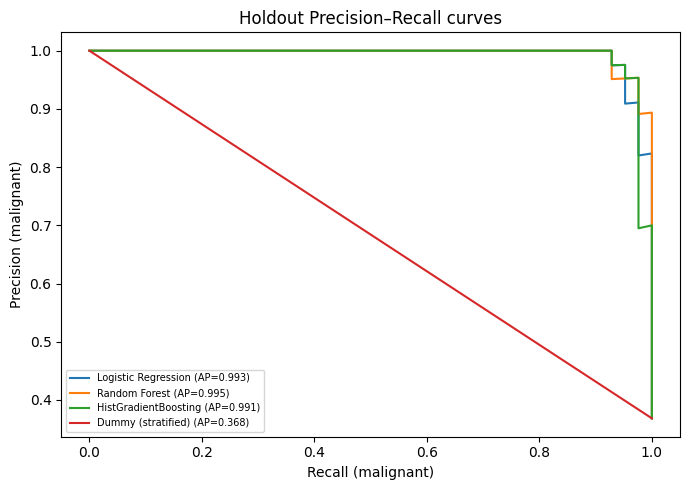

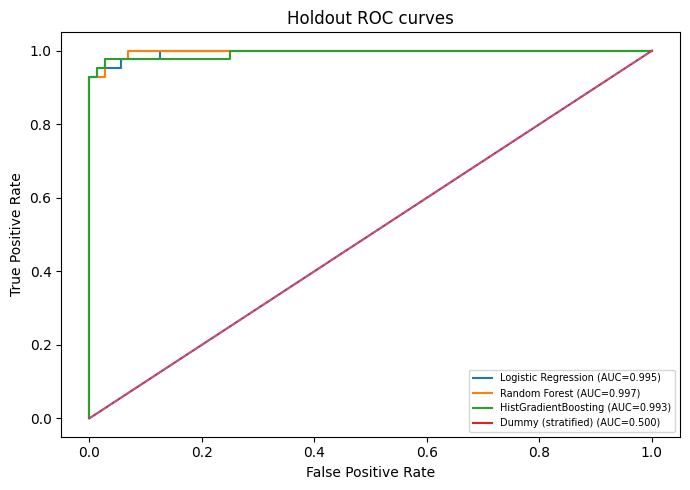

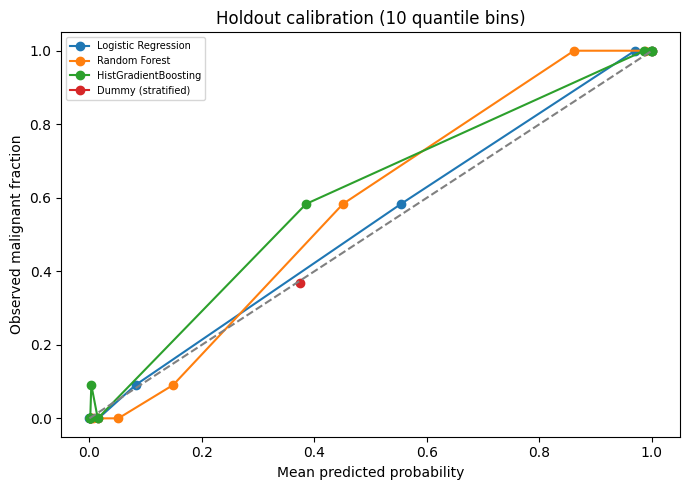

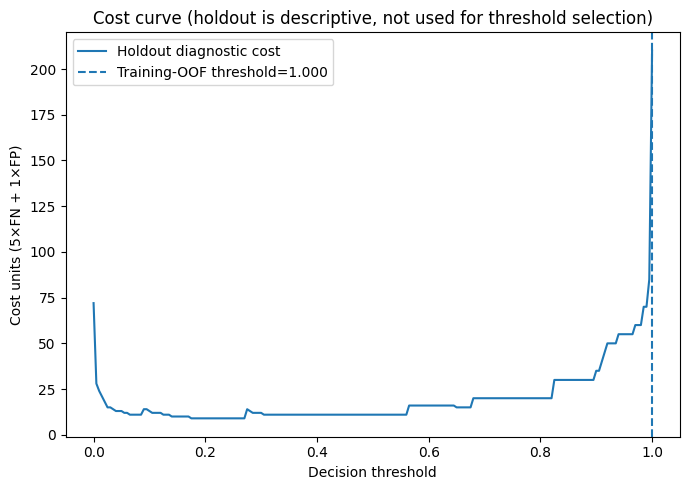

In [ ]:
# -------------------------- Visualizations ----------------------------
plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    precision, recall, _ = precision_recall_curve(y_test, probability)
    plt.plot(recall, precision, label=f"{name} (AP={average_precision_score(y_test, probability):.3f})")
plt.xlabel("Recall (malignant)"); plt.ylabel("Precision (malignant)")
plt.title("Holdout Precision–Recall curves"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "precision_recall.png", dpi=160); plt.show(); plt.close()

plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, probability)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probability):.3f})")
plt.plot([0, 1], [0, 1], "--", linewidth=1)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Holdout ROC curves"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "roc.png", dpi=160); plt.show(); plt.close()

plt.figure(figsize=(7, 5))
for name, probability in test_prob.items():
    observed, predicted = calibration_curve(y_test, probability, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, marker="o", label=name)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("Mean predicted probability"); plt.ylabel("Observed malignant fraction")
plt.title("Holdout calibration (10 quantile bins)"); plt.legend(fontsize=7); plt.tight_layout()
plt.savefig(FIG_DIR / "calibration.png", dpi=160); plt.show(); plt.close()

# Cost curve is visualized on holdout only as a diagnostic; it is NOT used to select threshold.
threshold_grid = np.linspace(0, 1, 201)
costs = []
for threshold in threshold_grid:
    pred = (chosen_probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    costs.append(FN_COST * fn + FP_COST * fp)
plt.figure(figsize=(7, 5))
plt.plot(threshold_grid, costs, label="Holdout diagnostic cost")
plt.axvline(chosen_threshold, linestyle="--",
            label=f"Training-OOF threshold={chosen_threshold:.3f}")
plt.xlabel("Decision threshold"); plt.ylabel("Cost units (5×FN + 1×FP)")
plt.title("Cost curve (holdout is descriptive, not used for threshold selection)")
plt.legend(); plt.tight_layout()
plt.savefig(FIG_DIR / "cost_curve.png", dpi=160); plt.show(); plt.close()


### For view Environment and final audit record


In [ ]:
# -------------------------- Environment and final audit record ----------
environment = {
    "python": sys.version.split()[0], "platform": platform.platform(),
    "numpy": np.__version__, "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__, "scipy": scipy.__version__,
    "matplotlib": plt.matplotlib.__version__, "seed": SEED,
    "folds": N_SPLITS, "test_size": TEST_SIZE, "bootstrap_replicates": N_BOOT,
    "dataset": "Wisconsin Breast Cancer Diagnostic (scikit-learn packaged copy)",
    "dataset_source": "https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic",
    "rows": int(len(X)), "features": int(X.shape[1]),
    "positive_class": "malignant (1)", "negative_class": "benign (0)",
    "selected_model_by_training_cv_pr_auc": selected_model,
    "selected_threshold_for_operational_rule": chosen_threshold
}
(OUTPUT_DIR / "environment.json").write_text(json.dumps(environment, indent=2))

print("\nCROSS-VALIDATION SUMMARY")
display(cv_summary.round(4))
print("\nUNTOUCHED HOLDOUT METRICS (threshold 0.50)")
display(holdout_metrics.round(4))
print("\nTHRESHOLD DECISION RECORD")
display(threshold_table.round(4))
print("\nERROR SLICES")
display(slice_table.round(4))
print(f"\nSelected model (training CV PR-AUC only): {selected_model}")
print(f"Threshold: {chosen_threshold:.6f}; costs: FN={FN_COST}, FP={FP_COST}; "
      f"training alert capacity={MAX_ALERT_RATE:.0%}")
print(f"Outputs written to: {OUTPUT_DIR.resolve()}")



CROSS-VALIDATION SUMMARY


,model,ROC_AUC_mean,ROC_AUC_sd,PR_AUC_mean,PR_AUC_sd,Brier_mean,Brier_sd,roc_auc_ci_low,roc_auc_ci_high,pr_auc_ci_low,pr_auc_ci_high,brier_ci_low,brier_ci_high
0,Dummy (stratified),0.5000,0.0000,0.3736,0.0000,0.2340,0.0000,0.5000,0.5000,0.3736,0.3736,0.2340,0.2340
1,HistGradientBoosting,0.9931,0.0039,0.9907,0.0041,0.0273,0.0110,0.9882,0.9979,0.9856,0.9958,0.0136,0.0409
2,Logistic Regression,0.9954,0.0053,0.9944,0.0052,0.0201,0.0060,0.9888,1.0000,0.9880,1.0000,0.0126,0.0275
3,Random Forest,0.9892,0.0061,0.9872,0.0059,0.0330,0.0086,0.9816,0.9967,0.9799,0.9945,0.0223,0.0437



UNTOUCHED HOLDOUT METRICS (threshold 0.50)


,model,ROC_AUC,PR_AUC,Brier,ECE_10bin,LogLoss,Accuracy_at_0.5,Precision_at_0.5,Recall_at_0.5,F1_at_0.5,TN,FP,FN,TP
0,Logistic Regression,0.9954,0.9931,0.0222,0.0253,0.0786,0.9737,0.9756,0.9524,0.9639,71,1,2,40
1,Random Forest,0.9970,0.9952,0.0290,0.0556,0.1085,0.9649,0.9750,0.9286,0.9512,71,1,3,39
2,HistGradientBoosting,0.9931,0.9912,0.0269,0.0290,0.1059,0.9649,1.0000,0.9048,0.9500,72,0,4,38
3,Dummy (stratified),0.5000,0.3684,0.2327,0.0052,0.6582,0.6316,0.0000,0.0000,0.0000,72,0,42,0



THRESHOLD DECISION RECORD


,model,threshold_from_training_oof,holdout_alert_rate,holdout_TP,holdout_FP,holdout_FN,holdout_TN,holdout_cost,FN_cost,FP_cost,training_alert_capacity
0,Logistic Regression,0.9996,0.1667,19,0,23,72,115.0,5.0,1.0,0.2
1,Random Forest,0.9770,0.1930,22,0,20,72,100.0,5.0,1.0,0.2
2,HistGradientBoosting,0.9980,0.1930,22,0,20,72,100.0,5.0,1.0,0.2
3,Dummy (stratified),1.0000,0.0000,0,0,42,72,210.0,5.0,1.0,0.2



ERROR SLICES


,slice_feature,slice,n,malignant_n,recall_malignant,false_negative_n,false_positive_n
0,radius_slice,Above train median,58,40,0.4750,21,0
1,radius_slice,At/below train median,56,2,0.0000,2,0
2,texture_slice,Above train median,51,33,0.4545,18,0
3,texture_slice,At/below train median,63,9,0.4444,5,0



Selected model (training CV PR-AUC only): Logistic Regression
Threshold: 0.999612; costs: FN=5.0, FP=1.0; training alert capacity=20%
Outputs written to: /content/ds_a4_outputs
